# Introduction to ODIN

ODIN is the **neutron imaging** instrument of the European Spallation Source (ESS). It takes pictures *through*
objects, as an X-ray machine does, but with neutrons. This page explains how it works and what it is used for, before
you measure with it. There is nothing to compute by hand and no code: read, try the pictures, answer the questions.
About 40 minutes.

**What you will know at the end**
1. what a neutron picture shows that an X-ray picture does not;
2. the parts of ODIN, from the source to the camera;
3. how the size of a hole sets the sharpness of the picture;
4. how ODIN knows the wavelength of each neutron: the time of flight;
5. what the choppers are for;
6. which exercises of the catalogue use which capability.

In [ ]:
import sys, os, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import quiz, intro_widgets as iw
q = quiz.Quiz("odin_intro")

## 1. A picture made with neutrons

In a **radiograph**, a beam crosses an object and a camera behind it records what comes through: the parts that stop
more of the beam look darker. X-rays are stopped by electrons, so heavy elements (metals) stop them most. Neutrons
are stopped by atomic nuclei, and the rule is different: **hydrogen and lithium stop neutrons strongly, while many
metals (aluminium, iron, lead) let most of them through**. A neutron picture therefore shows water inside a metal pipe, the
lithium moving in a battery, or the glue in a turbine blade.

The fraction of the beam that comes through is the **transmission** $T$, between 0 (everything stopped) and 1
(nothing stopped).

In [ ]:
q.choice("You want to see where the water is inside a running fuel cell with steel plates. Which beam do you choose, "
         "and why?",
         ["Neutrons: they cross the steel and are stopped by the hydrogen of the water.",
          "X-rays: they are stopped by the hydrogen of the water.",
          "Either: both give the same picture.",
          "Neutrons: they are stopped by the steel, which outlines the cell."],
         answer=0, why={1: "X-rays are stopped by electrons: the steel stops them far more than the water, which stays "
                           "invisible behind it.",
                        2: "The two beams are stopped by different things (electrons for X-rays, nuclei for neutrons): "
                           "the pictures differ.",
                        3: "Steel lets most neutrons through; it is the hydrogen that stops them."},
         explanation="Neutrons see light elements such as hydrogen through centimeters of metal: the classic use of "
                     "neutron imaging.", hints=["Which element stops neutrons strongly?"], title="Q1. Neutrons or X-rays?")

## 2. ODIN, from the source to the camera

ESS makes neutrons in **pulses**: 14 times per second, for 2.86 ms, protons hit a tungsten target, and a
**moderator** (cold hydrogen and water) slows the neutrons down. ODIN is 60 m long:

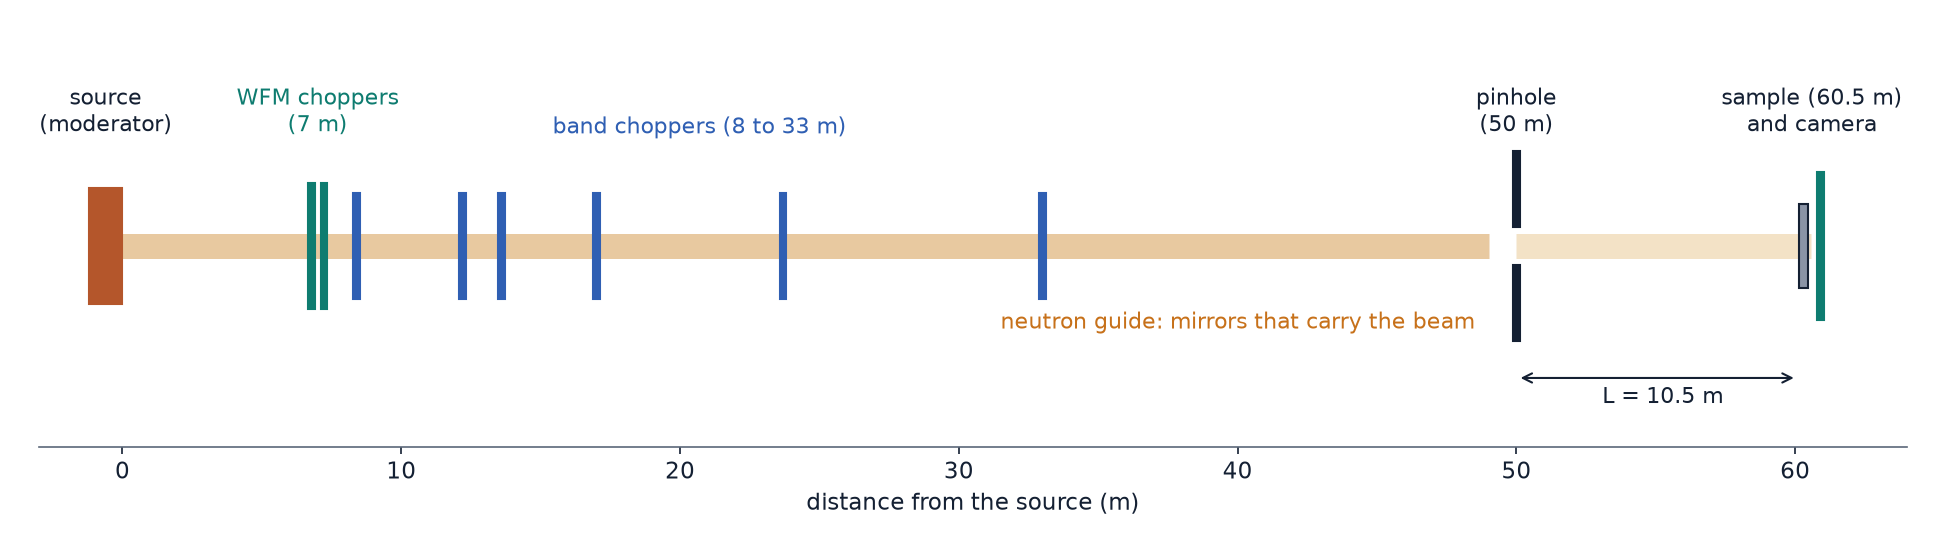

*ODIN from the source to the camera (distances of the official McStas model of ODIN).*

- the **choppers** (rotating discs with openings, between 7 and 33 m) let neutrons pass only at chosen times (part 5);
- the **neutron guide** (a tube of mirrors) carries the beam over 49 m without losing it;
- the **pinhole**, at 50 m, is a hole of 1 to 4 cm: seen from the sample, it is the source of the beam (part 3);
- the **sample** is at 60.5 m, on a stage that moves and turns it;
- the **camera** just behind it records each neutron: where it arrived (which pixel) and when (part 4).

In [ ]:
q.number("ESS sends 14 pulses per second. How many milliseconds are there between the starts of two pulses?",
         value=71.4, tol=0.6, unit="ms",
         mistakes=[(2.86, "the length of one pulse, not the time between two pulses"), (14, "the number of pulses per "
                   "second; the time between two is 1 s / 14")],
         hints=["One second holds 14 equal intervals.", "1000 ms / 14."],
         explanation="1000 ms / 14 = 71.4 ms. Keep this number: it comes back in part 5.", title="Q2. Between two pulses")

## 3. The pinhole: sharp or bright?

ODIN works like a **pinhole camera**. Each point of the sample is lit by the whole opening of the pinhole, of side
$D$, at a distance $L$ = 10.5 m. Behind the sample, the rays from the two edges of the hole spread apart again: on a
camera at a distance $l$ behind the sample, a point becomes a spot of width
$$\text{blur} = l \times \frac{D}{L}.$$

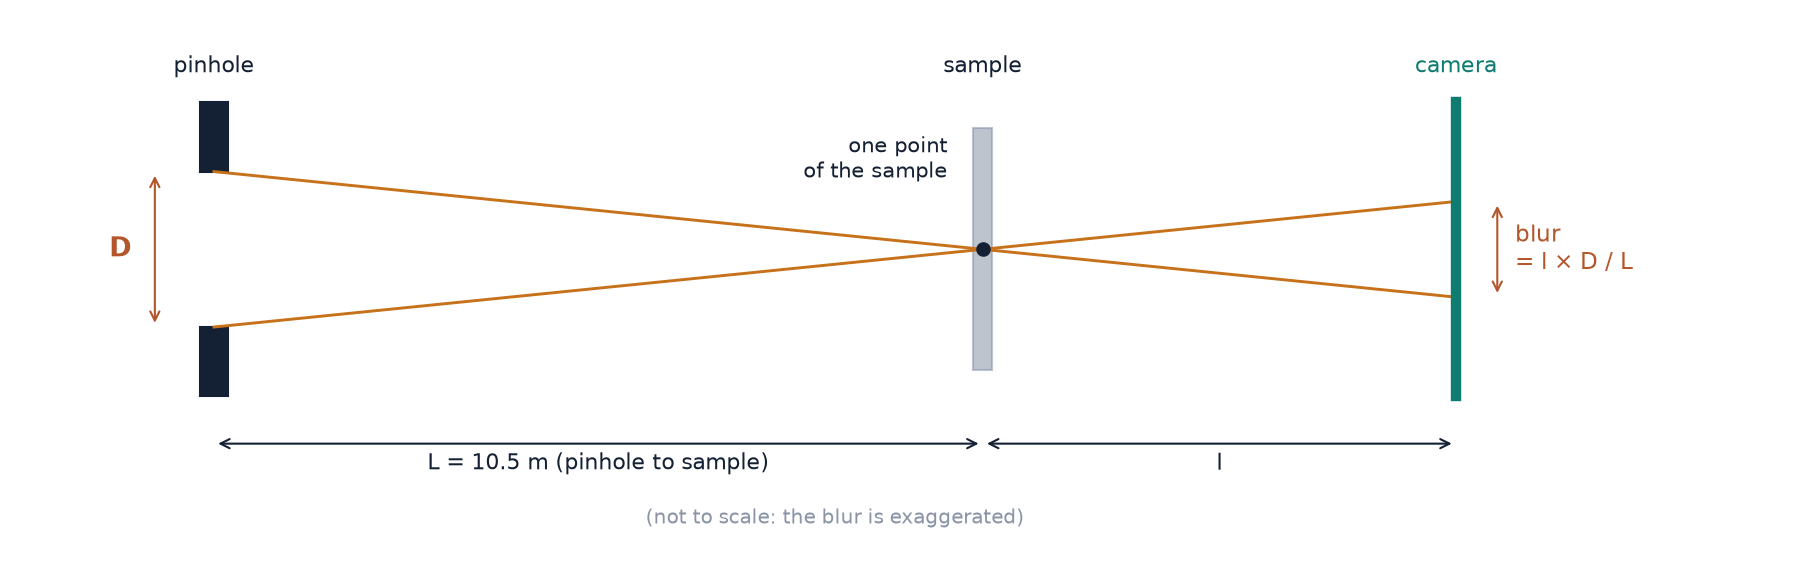

*Why a point of the sample becomes a spot on the camera: the rays from the two edges of the pinhole cross at the point and spread apart behind it.*

The ratio $L/D$ is the **collimation ratio**: the larger, the sharper the picture. But the neutrons that reach the
sample are those that pass the hole: their number goes with its **area**, $D^2$. A small pinhole gives a sharp but
dark, hence noisy, picture. Try it: the picture below is a test pattern of bars of four widths.

In [ ]:
iw.odin_pinhole()

In [ ]:
q.number("With the 3 cm pinhole (L = 10.5 m), what is the collimation ratio L/D?", value=350, tol=5, unit="",
         mistakes=[(3.5, "mind the units: 10.5 m = 1050 cm"), (0.00286, "D/L, the inverse")],
         hints=["Use the same unit for both: L = 1050 cm.", "1050 / 3."],
         explanation="1050 cm / 3 cm = 350. With the camera 5 cm behind the sample the blur is 5 cm / 350 = 0.14 mm.",
         title="Q3. Collimation ratio")
q.choice("You change the pinhole from 3 cm to 1 cm, and count for the same time. What happens to the picture?",
         ["3 times sharper, with 9 times fewer neutrons: noisier.",
          "3 times sharper, with 3 times fewer neutrons.",
          "9 times sharper, with 3 times fewer neutrons.",
          "Sharper and brighter: a smaller hole concentrates the beam."],
         answer=0, why={1: "The blur goes with D (3 times), but the neutrons go with the area of the hole, D²: 9 times.",
                        2: "The other way round: the blur goes with D, the number of neutrons with D².",
                        3: "A hole only lets through what falls on it: a smaller hole means fewer neutrons."},
         explanation="Blur = l·D/L: 3 times smaller. Neutrons through the hole ∝ D²: 9 times fewer. To keep the same "
                     "noise you would have to count 9 times longer.",
         hints=["How does the blur depend on D?", "How does the area of a square hole depend on its side?"],
         title="Q4. Sharp or bright?")

## 4. Time of flight: the clock that measures the wavelength

A neutron is also a wave. Its **wavelength** $\lambda$ depends only on its speed $v$: slow neutrons have a long
wavelength,
$$\lambda\,[\text{Å}] = \frac{3956}{v\,[\text{m/s}]}$$
(1 Å = 0.1 nm, about the distance between two atoms). The wavelength matters because it decides how a material stops
the neutron: the transmission of a crystal changes abruptly at certain wavelengths (the Bragg edges of the exercise
on iron).

All the neutrons of a pulse leave the source at almost the same time, but the slow ones arrive later. So the
**arrival time** at the camera, 60.55 m away, tells the speed, hence the wavelength. This is the **time of flight**:

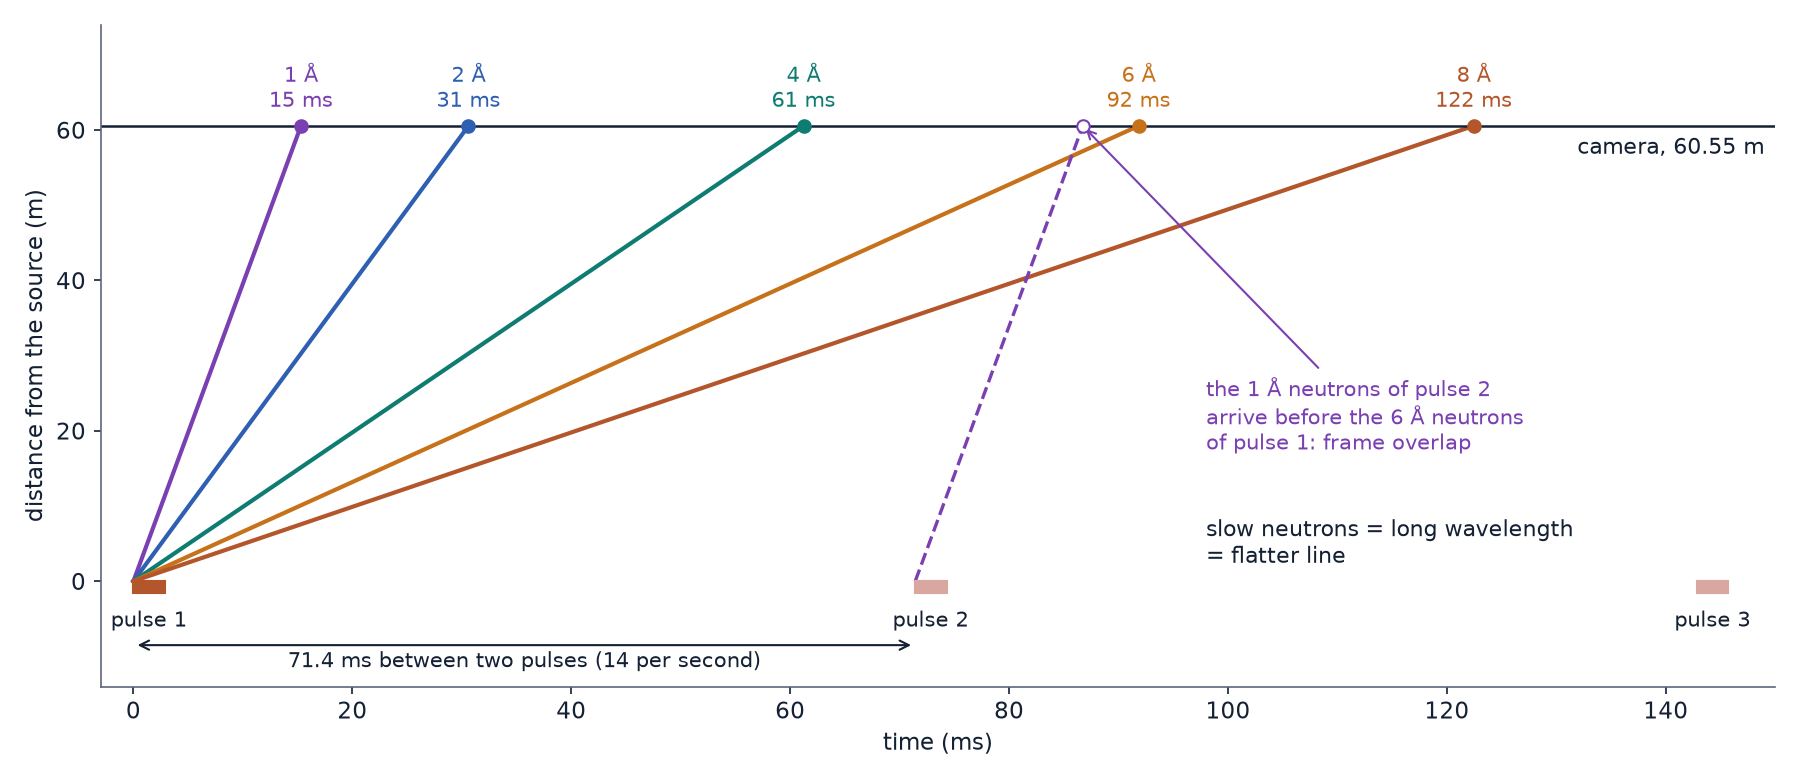

*Distance against time. Each line is a neutron of pulse 1: the slower it is (the longer its wavelength), the flatter its line and the later it reaches the camera.*

Try it: choose a wavelength and see when the neutron arrives.

In [ ]:
iw.odin_time_of_flight()

In [ ]:
q.number("A neutron of 4 Å travels at 3956 / 4 = 989 m/s. How long does it take to reach the camera, 60.55 m away?",
         value=61.2, tol=1.0, unit="ms",
         mistakes=[(0.0612, "right, but in seconds: give it in milliseconds"), (16.3, "you divided the speed by the "
                   "distance; time = distance / speed")],
         hints=["time = distance / speed.", "60.55 m / 989 m/s = 0.0612 s."],
         explanation="60.55 / 989 = 0.0612 s = 61.2 ms. Twice the wavelength is half the speed, hence twice the time: "
                     "the arrival time is proportional to λ.", title="Q5. Arrival time")
q.choice("The camera records a neutron 30.6 ms after the pulse. Which wavelength does it have?",
         ["2 Å", "4 Å", "1 Å", "8 Å"], answer=0,
         why={1: "A 4 Å neutron needs 61.2 ms (Q5). This one arrived in half that time.",
              2: "A 1 Å neutron is 4 times faster than a 4 Å one: 15.3 ms.",
              3: "An 8 Å neutron is the slowest of the four: 122 ms."},
         explanation="The arrival time is proportional to λ: half the time of a 4 Å neutron means half the wavelength, "
                     "2 Å. This is exactly what the ESS software does for every neutron of your files.",
         hints=["Compare with the 61.2 ms of a 4 Å neutron."], title="Q6. From the time to the wavelength")

## 5. The choppers: keeping the pulses apart, and sharpening them

**Two problems** with the simple picture of part 4.

**Problem 1: the pulses overlap.** A new pulse leaves every 71.4 ms. Look again at the figure of part 4: a 6 Å
neutron of pulse 1 needs 92 ms, so it arrives *after* the fast neutrons of pulse 2. The camera cannot tell them
apart: this is **frame overlap**. Between two pulses the camera can only sort a band of wavelengths
$3956 \times 0.0714 / 60.55$ = **4.7 Å** wide. ODIN's *band choppers* turn at 7 turns per second and let through
**one pulse in two**: the pulses are then 143 ms apart, and a band of about 9 Å (1 to 9 Å) fits without overlap.

**Problem 2: the pulse is long.** The neutrons do not leave at one instant but during 2.86 ms. Two neutrons of the
same wavelength can thus arrive 2.86 ms apart, and the clock mistakes this for a difference of wavelength of
$3956 \times 0.00286 / 60.55$ = **0.19 Å**. At 4 Å this is an uncertainty of about 5 %: too coarse to measure, for
instance, how much a metal is stretched (0.1 %). The *WFM choppers* (wavelength frame multiplication), 7 m from
the source, cut the long pulse into six short ones: the wavelength is then known to **0.2 to 0.8 %**, at a price:
only **3 % of the neutrons** are left.

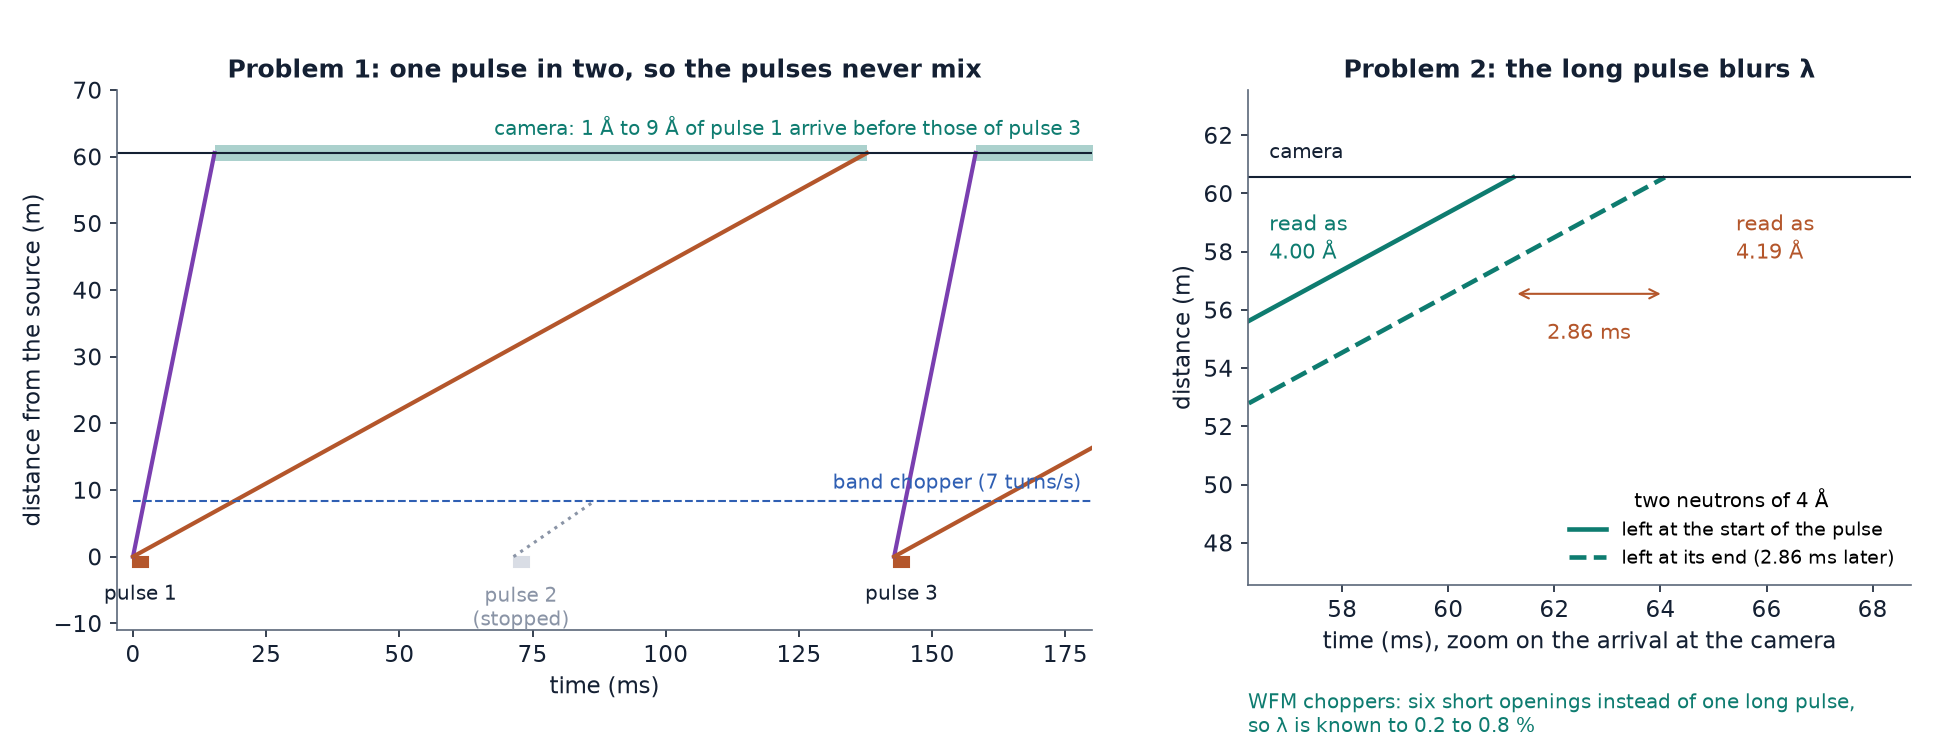

*Left: the band choppers stop one pulse in two, so the neutrons of 1 to 9 Å of a pulse reach the camera before those of the next one. Right: two neutrons of the same wavelength leaving at the start and at the end of the long pulse arrive 2.86 ms apart, and are read as different wavelengths.*

Hence the three chopper settings of the twin, which you will choose yourself in the exercises:

| Chopper mode | What turns | Wavelengths | Wavelength known to | Neutrons |
|---|---|---|---|---|
| `white` | nothing | all, mixed | not measured | all (100 %) |
| `natural` | band choppers | 1 to 9 Å | 0.19 Å (2 to 10 %) | about half (one pulse in two) |
| `wfm` | band + WFM choppers | 1 to 9 Å | 0.2 to 0.8 % | 3 % |

In [ ]:
q.choice("Why do the band choppers of ODIN let through only one pulse in two?",
         ["So that the slow neutrons of one pulse do not arrive mixed with the fast neutrons of the next.",
          "To protect the camera from too many neutrons.",
          "To make the neutrons slower.",
          "To make the picture sharper."],
         answer=0, why={1: "The camera stands the full beam; the point is to know which pulse each neutron comes from.",
                        2: "A chopper does not change the speed of a neutron: it only lets it pass or stops it.",
                        3: "The sharpness of the picture is set by the pinhole (part 3)."},
         explanation="With pulses 71.4 ms apart only a 4.7 Å band can be sorted by arrival time; with one pulse in two, "
                     "about 9 Å.", hints=["Look at the dashed line of the figure of part 4."], title="Q7. One pulse in two")
q.number("Without the WFM choppers, the wavelength is known to 0.19 Å. What is this uncertainty, in percent, for a "
         "neutron of 4 Å?", value=4.7, tol=0.4, unit="%",
         mistakes=[(0.047, "right, but as a fraction: multiply by 100"), (21, "you divided 4 by 0.19; the other way round")],
         hints=["Relative uncertainty = 0.19 / 4.", "0.19 / 4 = 0.047."],
         explanation="0.19 / 4 = 4.7 %. For 2 Å it is 9 %, for 9 Å 2 %: the long wavelengths are known best.",
         title="Q8. How well is the wavelength known?")
q.choice("You must measure how much a steel part is stretched: its Bragg edge moves by 0.1 % of its wavelength. "
         "Which chopper mode do you choose?",
         ["wfm: the only one that knows the wavelength well enough, even with fewer neutrons.",
          "white: the most neutrons, so the best measurement.",
          "natural: a good compromise.",
          "Any: the mode does not matter for an edge."],
         answer=0, why={1: "In white mode the wavelength is not measured at all: no edge can be seen.",
                        2: "Natural mode knows the wavelength to about 5 % at 4 Å: 50 times too coarse for 0.1 %.",
                        3: "It does: the edge is smeared by the uncertainty of the wavelength."},
         explanation="Only WFM reaches a fraction of a percent. The price is 3 % of the neutrons, so a longer count: "
                     "the trade-off between resolution and counting time comes back in every exercise.",
         hints=["Compare 0.1 % with the last-but-one column of the table."], title="Q9. Which mode?")

## 6. What ODIN is used for

Everything ODIN does combines the three ingredients of this page: a picture (part 3), a wavelength for every neutron
(part 4), and a choice of resolution (part 5). The catalogue of the app has, or will have, an exercise for each use:

| What you look at | What it tells | Typical question | In the catalogue |
|---|---|---|---|
| The picture itself, all wavelengths | where the material is | Where is the water in this fuel cell? | planned |
| Many pictures while the sample turns (**tomography**) | the object in 3D | What is inside this object? | *Inside an object without opening it* (planned) |
| The transmission against the wavelength: **Bragg edges** | the crystal structure, the distance between atoms | Is this steel ferritic? | **How far apart are the atoms in iron?** · **Unknown metals** (game) |
| The exact position of an edge (WFM mode) | how much the material is stretched | Where is this weld under stress? | planned |
| A sample that changes with time | what happens during operation | How does lithium enter a battery electrode? | planned |
| The spin of the neutrons (**polarized** imaging) | magnetic fields inside matter | What is the field inside this coil? | *Magnetic fields made visible* (planned) |

Start with **How far apart are the atoms in iron?**: you will choose the chopper mode and the pinhole, measure a
plate of iron, and read the distance between its atoms from the Bragg edges.

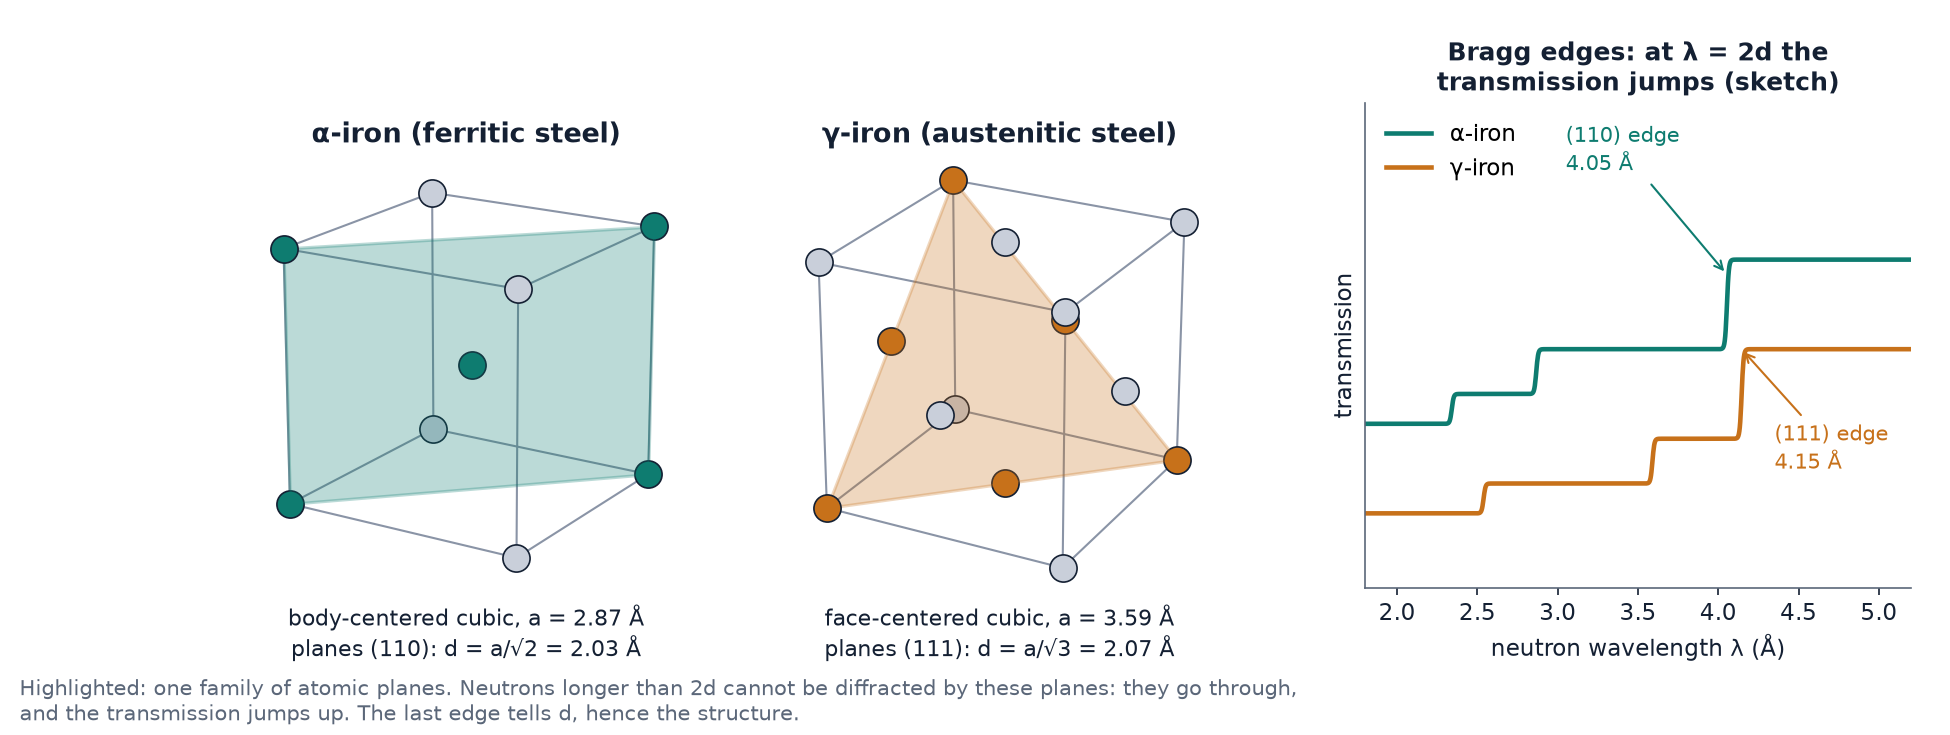

*The first exercise: tell two crystal structures of iron apart by their Bragg edges, the wavelengths at which the transmission jumps.*

In [ ]:
q.choice("A colleague wants to know whether a part is made of ferritic or austenitic steel, without cutting it. "
         "What should ODIN measure?",
         ["The transmission as a function of the wavelength: the Bragg edges give the crystal structure.",
          "One picture with all wavelengths: the two steels have different shades.",
          "A tomography: the structure is seen in 3D.",
          "The magnetic field with polarized neutrons."],
         answer=0, why={1: "Both are iron: they stop about the same number of neutrons, the shades are almost equal.",
                        2: "A tomography shows the shape of the part, not the arrangement of its atoms.",
                        3: "Ferritic steel is magnetic and austenitic is not, but this is an indirect and harder way; "
                           "the Bragg edges answer directly."},
         explanation="The edges are at λ = 2d, where d is a distance between planes of atoms: each crystal structure "
                     "has its own. This is the first exercise of the catalogue.",
         hints=["Which line of the table speaks of the crystal structure?"], title="Q10. Which measurement?")
q.report()

**Next.** Close this tab and open *How far apart are the atoms in iron?* in the catalogue.